<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan2/BTOL/MachineLearningT2_BTVN_Bai2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc Boston: (506, 13)
5 dong du lieu:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   

   PTRATIO       B  LSTAT  
0     15.3  396.90   4.98  
1     17.8  396.90   9.14  
2     17.8  392.83   4.03  
3     18.7  394.63   2.94  
4     18.7  396.90   5.33  
Gia tri thieu: 0
K=3 | MSE=19.4043 | R2=0.7354
K=5 | MSE=20.6055 | R2=0.7190
K=7 | MSE=23.4155 | R2=0.6807
K=9 | MSE=24.0094 | R2=0.6726

BANG KET QUA:
 K     MSE     R2
 3 19.4043 0.7354
 5 20.6055 0.7190
 7 23.4155 0.6807
 9 24.0094 0.6726
K co MSE thap nhat trong cac ket qua test: 3


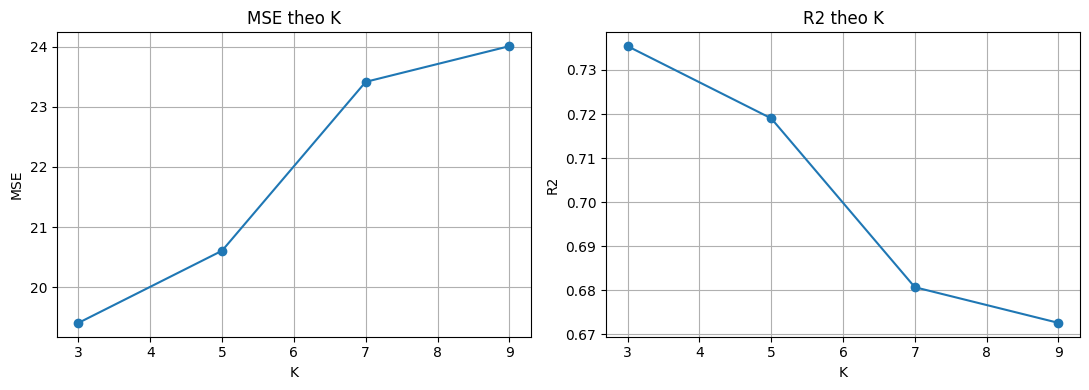

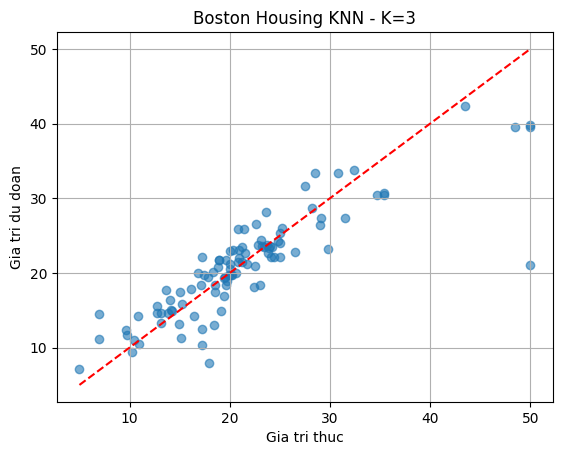

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tai Boston Housing tu OpenML
boston = fetch_openml(data_id=531, as_frame=True)

X = boston.data.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(boston.target, errors="coerce")

valid = X.notna().all(axis=1) & y.notna()
X, y = X.loc[valid], y.loc[valid]

print("Kich thuoc Boston:", X.shape)
print("5 dong du lieu:")
print(X.head())
print("Gia tri thieu:", X.isna().sum().sum())

# 2. Chia du lieu 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Chuan hoa
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 4. Thu nhieu gia tri K
results = []

for k in [3, 5, 7, 9]:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_s, y_train)

    y_pred = model.predict(X_test_s)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({"K": k, "MSE": mse, "R2": r2})

    print(f"K={k} | MSE={mse:.4f} | R2={r2:.4f}")

df = pd.DataFrame(results)
print("\nBANG KET QUA:")
print(df.round(4).to_string(index=False))

best_k = int(df.loc[df["MSE"].idxmin(), "K"])
print("K co MSE thap nhat trong cac ket qua test:", best_k)

# 5. Ve MSE va R2 theo K
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(df["K"], df["MSE"], marker="o")
axes[0].set_title("MSE theo K")
axes[0].set_xlabel("K")
axes[0].set_ylabel("MSE")
axes[0].grid()

axes[1].plot(df["K"], df["R2"], marker="o")
axes[1].set_title("R2 theo K")
axes[1].set_xlabel("K")
axes[1].set_ylabel("R2")
axes[1].grid()

plt.tight_layout()
plt.show()

# 6. Ve gia tri thuc va du doan
model = KNeighborsRegressor(n_neighbors=best_k)
model.fit(X_train_s, y_train)
pred = model.predict(X_test_s)

plt.scatter(y_test, pred, alpha=0.6)
low = min(np.min(y_test), np.min(pred))
high = max(np.max(y_test), np.max(pred))
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Gia tri thuc")
plt.ylabel("Gia tri du doan")
plt.title(f"Boston Housing KNN - K={best_k}")
plt.grid()
plt.show()
